In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Read the Excel file
# Replace 'your_file.xlsx' with your actual file path
df = pd.read_excel('../misc_data/LongitudinalSpermSampling_SuccessSummary.xlsx')

# Alternatively, if you have a CSV file:
# df = pd.read_csv('../your_file.csv')

In [3]:
# Extract time points from column headers (assuming they're in format like "4.86mo", "5.76mo", etc.)
time_columns = [col for col in df.columns if col != 'fishID']
time_points = []

for col in time_columns:
    # Extract numeric value from column name (e.g., "4.86mo" -> 4.86)
    try:
        time_val = float(col.replace('mo', '').strip())
        # Keep original values (don't round)
        time_points.append(time_val)
    except:
        continue
display(time_points)

[4.86,
 5.76,
 6.73,
 7.86,
 8.86,
 9.93,
 11.0,
 12.1,
 13.2,
 14.23,
 16.1,
 17.13,
 18.4,
 20.53,
 22.43,
 23.6,
 24.7,
 25.6,
 27.0]

In [4]:
# Sort fish IDs into three groups with gaps
def count_data_points(row):
    """Count the number of alive observations (1, 2, or 3) for each fish"""
    count = 0
    for col in time_columns:
        cell_value = str(row[col]).strip().lower()
        if cell_value in ['1', '2', '3']:
            count += 1
    return count

In [5]:
# Add data point count to dataframe
df['data_point_count'] = df.apply(count_data_points, axis=1)

In [6]:
# Separate into three groups
ctrl_fish = df[df['fishID'].astype(str).str.contains('ctrl', case=False)].copy()
special_fish = df[df['fishID'].isin(['fish11', 'fish30', 'fish46'])].copy()
regular_fish = df[~df['fishID'].astype(str).str.contains('ctrl', case=False) & 
                   ~df['fishID'].isin(['fish11', 'fish30', 'fish46'])].copy()

In [7]:
# Extract numeric fish ID for secondary sorting
def extract_fish_number(fish_id):
    """Extract the numeric part from fishID (e.g., 'fish14' -> 14)"""
    num = ''.join(filter(str.isdigit, str(fish_id)))
    return int(num) if num else 999

regular_fish['fish_number'] = regular_fish['fishID'].apply(extract_fish_number)
ctrl_fish['fish_number'] = ctrl_fish['fishID'].apply(extract_fish_number)

# Sort regular fish by data point count (descending), then by fish number (ascending)
regular_fish = regular_fish.sort_values(['data_point_count', 'fish_number'], ascending=[False, True])

# Sort ctrl fish by fish number only (ascending)
ctrl_fish = ctrl_fish.sort_values('fish_number', ascending=True)

# Drop the temporary column
regular_fish = regular_fish.drop('fish_number', axis=1)
ctrl_fish = ctrl_fish.drop('fish_number', axis=1)

In [8]:
# Sort special fish in specific order: fish11, fish46, fish30
special_order = ['fish11', 'fish46', 'fish30']
special_fish['sort_order'] = special_fish['fishID'].apply(lambda x: special_order.index(x) if x in special_order else 999)
special_fish = special_fish.sort_values('sort_order')
special_fish = special_fish.drop('sort_order', axis=1)

In [9]:
# Combine groups with gap indicators
# We'll use the index to create gaps later
regular_fish['group'] = 'regular'
special_fish['group'] = 'special'
ctrl_fish['group'] = 'ctrl'

In [10]:
# Concatenate in order: regular, special, ctrl
df = pd.concat([regular_fish, special_fish, ctrl_fish]).reset_index(drop=True)

In [11]:
# After extracting time_points, add this:
print(f"Number of time columns: {len(time_columns)}")
print(f"Time columns: {time_columns}")
print(f"Number of time points parsed: {len(time_points)}")
print(f"Time points: {time_points}")

Number of time columns: 22
Time columns: ['4.86mo', '5.76mo', '6.73mo', '7.86mo', '8.86mo', '9.93mo', '11mo', '12.1mo', '13.2mo', '14.23mo', '16.1mo', '17.13mo', '18.4mo', '20.53mo', '22.43mo', '23.6mo', '24.7mo', '25.6mo', '27mo', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22']
Number of time points parsed: 19
Time points: [4.86, 5.76, 6.73, 7.86, 8.86, 9.93, 11.0, 12.1, 13.2, 14.23, 16.1, 17.13, 18.4, 20.53, 22.43, 23.6, 24.7, 25.6, 27.0]


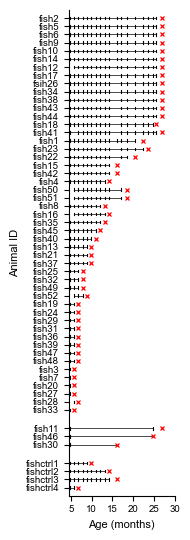

Processed 56 fish
Time range: 4.86 to 27.0 months


In [13]:
# Create the plot
plt.rcParams['font.family'] = 'Arial'
fig, ax = plt.subplots(figsize=(2, 5.5))

# Calculate y-positions with gaps
y_positions = []
current_y = 0
gap_size = 1.25  # Size of gap between groups
prev_group = None

for idx, row in df.iterrows():
    # Add gap when group changes
    if prev_group is not None and row['group'] != prev_group:
        current_y += gap_size
    
    y_positions.append(current_y)
    current_y += 1
    prev_group = row['group']

# Process each fish
for plot_idx, (df_idx, row) in enumerate(df.iterrows()):
    fish_id = row['fishID']
    y_pos = y_positions[plot_idx]
    
    # Get observation data for this fish
    observations = []
    death_time = None
    
    for i, col in enumerate(time_columns):
        if i < len(time_points):
            cell_value = str(row[col]).strip().lower()
            
            # Check if fish was alive (has 1, 2, or 3 in the value)
            if any(num in cell_value for num in ['1', '2', '3']):
                # Fish was alive/observed at this time point
                observations.append((time_points[i], 'alive'))
            
            # Check if fish died at this time point
            if 'dead' in cell_value:
                death_time = time_points[i]
            
            # Skip if value is 0 or empty
            if cell_value == '0':
                pass
    
    # Get alive observation times
    alive_times = [obs[0] for obs in observations if obs[1] == 'alive']
    
    # Draw line connecting all observations (alive times)
    if alive_times:
        # Sort times to draw line correctly
        alive_times_sorted = sorted(alive_times)
        
        # Determine end point for the line
        end_point = alive_times_sorted[-1]
        
        # Special cases: extend line to death point if specified
        if fish_id in ['fish30', 'fish46'] and death_time is not None:
            end_point = death_time
        
        # Draw horizontal line from first to last observation (or to death for special cases)
        ax.plot([alive_times_sorted[0], end_point], 
                [y_pos, y_pos], 'k-', linewidth=0.5)
        
        # Draw tick marks at each alive observation
        for time in alive_times:
            ax.plot([time, time], [y_pos - 0.15, y_pos + 0.15], 'k-', linewidth=0.8)
    
    # Plot death as red dot at the end
    if death_time is not None:
        ax.plot([death_time], [y_pos], 'rx', markersize=2.6, markeredgewidth=0.9)

# Formatting
ax.set_xlabel('Age (months)', fontsize=8)
ax.set_ylabel('Animal ID', fontsize=8)
ax.set_ylim(-1, current_y)
ax.set_xlim(4.5, max(time_points) + 2)  # Start at 4.5 to add space before first tick marks

# Convert months to years for x-axis labels
ax.set_xticks([5, 10, 15, 20, 25, 30])
ax.set_xticklabels(['5', '10', '15', '20', '25', '30'], fontsize=7)

# Invert y-axis so first fish is at top
ax.invert_yaxis()

# Add fishID labels on y-axis at correct positions
ax.set_yticks(y_positions)
ax.set_yticklabels(df['fishID'], fontsize=7)

# Remove border (spines) but keep axes
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("images/fish_lifespan.svg", bbox_inches='tight', transparent=True)
plt.savefig("images/fish_lifespan.png", dpi=600, bbox_inches='tight', transparent=True)
plt.show()

print(f"Processed {len(df)} fish")
print(f"Time range: {min(time_points)} to {max(time_points)} months")